# 04 - Explainability: *why does the model think this order will be late?*

**Purpose.** A risk score is only useful to an operations team if they can see *why* an order is
flagged and trust (or challenge) the reason. This notebook answers that at two levels:

1. **Global** - what does each model rely on overall, and do different explanation methods agree?
2. **Local** - for a single order, what pushed its risk up or down, in plain English?
   We walk through three mechanically chosen cases: a true positive, a false positive and a
   false negative.

**Three models, three explanation methods** (all expressed in the same unit - log-odds):

| model | how it is explained | exactness |
|---|---|---|
| Logistic regression (primary) | coefficient x feature value | exact decomposition |
| EBM (glass-box) | sum of learned shape functions + a few interactions | exact decomposition |
| LightGBM | TreeSHAP (Shapley values) | exact for the tree ensemble |

**Reading guide.** Positive contribution = pushes the order toward "late"; negative = pulls it
toward "on time"; contributions are relative to an average order. Related features are *grouped*
(for example three distance-related features become one reason) so one idea is never shown
twice. Inference cells are computed from data; I checked each claim against the executed output.

**Honesty note.** Explanations describe *what the model does*, not *what causes lateness*.

In [1]:
import warnings

warnings.filterwarnings("ignore")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from ontime.config import load_config, project_path
from ontime.explain import shap_explain
from ontime.explain.cases import case_summary, load_context, pick_cases
from ontime.explain.reason_codes import feature_to_group, group_contributions, load_templates
from ontime.features.build import FEATURE_COLUMNS

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_colwidth", 110)
CFG = load_config()
REP = project_path(CFG["paths"]["reports_dir"])
FIG = REP / "figures"
show = lambda name: display(Image(filename=str(FIG / name)))
pct = lambda v: f"{v:.0%}"
summary = json.loads((REP / "explain_summary.json").read_text())
templates = load_templates()
f2g = feature_to_group(templates)
ctx = load_context()  # test frames, models, contributions, reason codes
MODEL_NAMES = {"logreg": "Logistic regression", "lightgbm": "LightGBM", "ebm": "EBM"}

## 1. What does each model rely on? (global importance by reason group)
We average the absolute contribution of each *group of features* over the validation set
(global explanations are computed on validation, not test, so they are not tuned to test behaviour).

In [2]:
grp = pd.read_csv(REP / "global_importance_groups.csv", index_col=0)
grp.columns = [MODEL_NAMES[c] for c in grp.columns]
grp = grp.sort_values("LightGBM", ascending=False)
ax = grp.plot.barh(figsize=(9, 6), width=0.8)
ax.invert_yaxis()
ax.set_xlabel("Mean absolute contribution (log-odds)")
ax.set_title("Which reason groups drive predictions, by model (validation set)")
plt.tight_layout()
plt.show()
top = {m: grp[m].sort_values(ascending=False).index[:3].tolist() for m in grp.columns}
Markdown(
    "**Top-3 groups by model:** " + "; ".join(f"**{m}**: {', '.join(g)}" for m, g in top.items())
)

**Top-3 groups by model:** **Logistic regression**: payment, same_state, approval_timing; **LightGBM**: route_history, seller_record, distance; **EBM**: route_history, seller_record, distance

In [3]:
rk = summary["agreement"]["rank_agreement"]
tree_pair = rk["spearman"]["lightgbm vs ebm"]
lr_pairs = [rk["spearman"]["logreg vs lightgbm"], rk["spearman"]["logreg vs ebm"]]
Markdown(f"""
**Inference.**
- The two tree-based models agree closely on what matters (Spearman rank correlation
  **{tree_pair:.2f}**, top-10 feature overlap **{rk["top_k_overlap"]["lightgbm vs ebm"]:.0%}**). Both put most weight on
  *route history*, *seller record* and *distance* (their top-3 groups are identical).
- Logistic regression spreads its weight more evenly across many groups and agrees much less with
  them (rank correlation **{lr_pairs[0]:.2f}** and **{lr_pairs[1]:.2f}**, top-10 overlap
  **{rk["top_k_overlap"]["logreg vs lightgbm"]:.0%}** and **{rk["top_k_overlap"]["logreg vs ebm"]:.0%}**).
- A linear model must express everything through one weight per feature, so correlated features
  (several late-rate features, several weight/volume features) share and trade credit in ways a
  tree model does not. Disagreement here is a **warning not to read any single coefficient in
  isolation**, not evidence that one model is "wrong".
- Interesting: logistic regression was the *best out-of-time ranker* (Phase 7) while leaning on
  groups the tree models mostly ignore (for example payment and network delay). One hypothesis:
  broad, low-weight use of many stable features transfers better to a new period than heavy
  reliance on history features whose behaviour changed. This is a hypothesis, not proven here.
""")


**Inference.**
- The two tree-based models agree closely on what matters (Spearman rank correlation
  **0.78**, top-10 feature overlap **80%**). Both put most weight on
  *route history*, *seller record* and *distance* (their top-3 groups are identical).
- Logistic regression spreads its weight more evenly across many groups and agrees much less with
  them (rank correlation **0.41** and **0.40**, top-10 overlap
  **30%** and **50%**).
- A linear model must express everything through one weight per feature, so correlated features
  (several late-rate features, several weight/volume features) share and trade credit in ways a
  tree model does not. Disagreement here is a **warning not to read any single coefficient in
  isolation**, not evidence that one model is "wrong".
- Interesting: logistic regression was the *best out-of-time ranker* (Phase 7) while leaning on
  groups the tree models mostly ignore (for example payment and network delay). One hypothesis:
  broad, low-weight use of many stable features transfers better to a new period than heavy
  reliance on history features whose behaviour changed. This is a hypothesis, not proven here.


## 2. How does the EBM draw each feature's effect? (shape functions)
An EBM is a sum of one learned curve per feature, so its picture **is** its explanation. Each panel
shows the effect on the log-odds of being late as the feature value changes (shaded band = model
uncertainty across bags). Zero means "no effect relative to the average order".

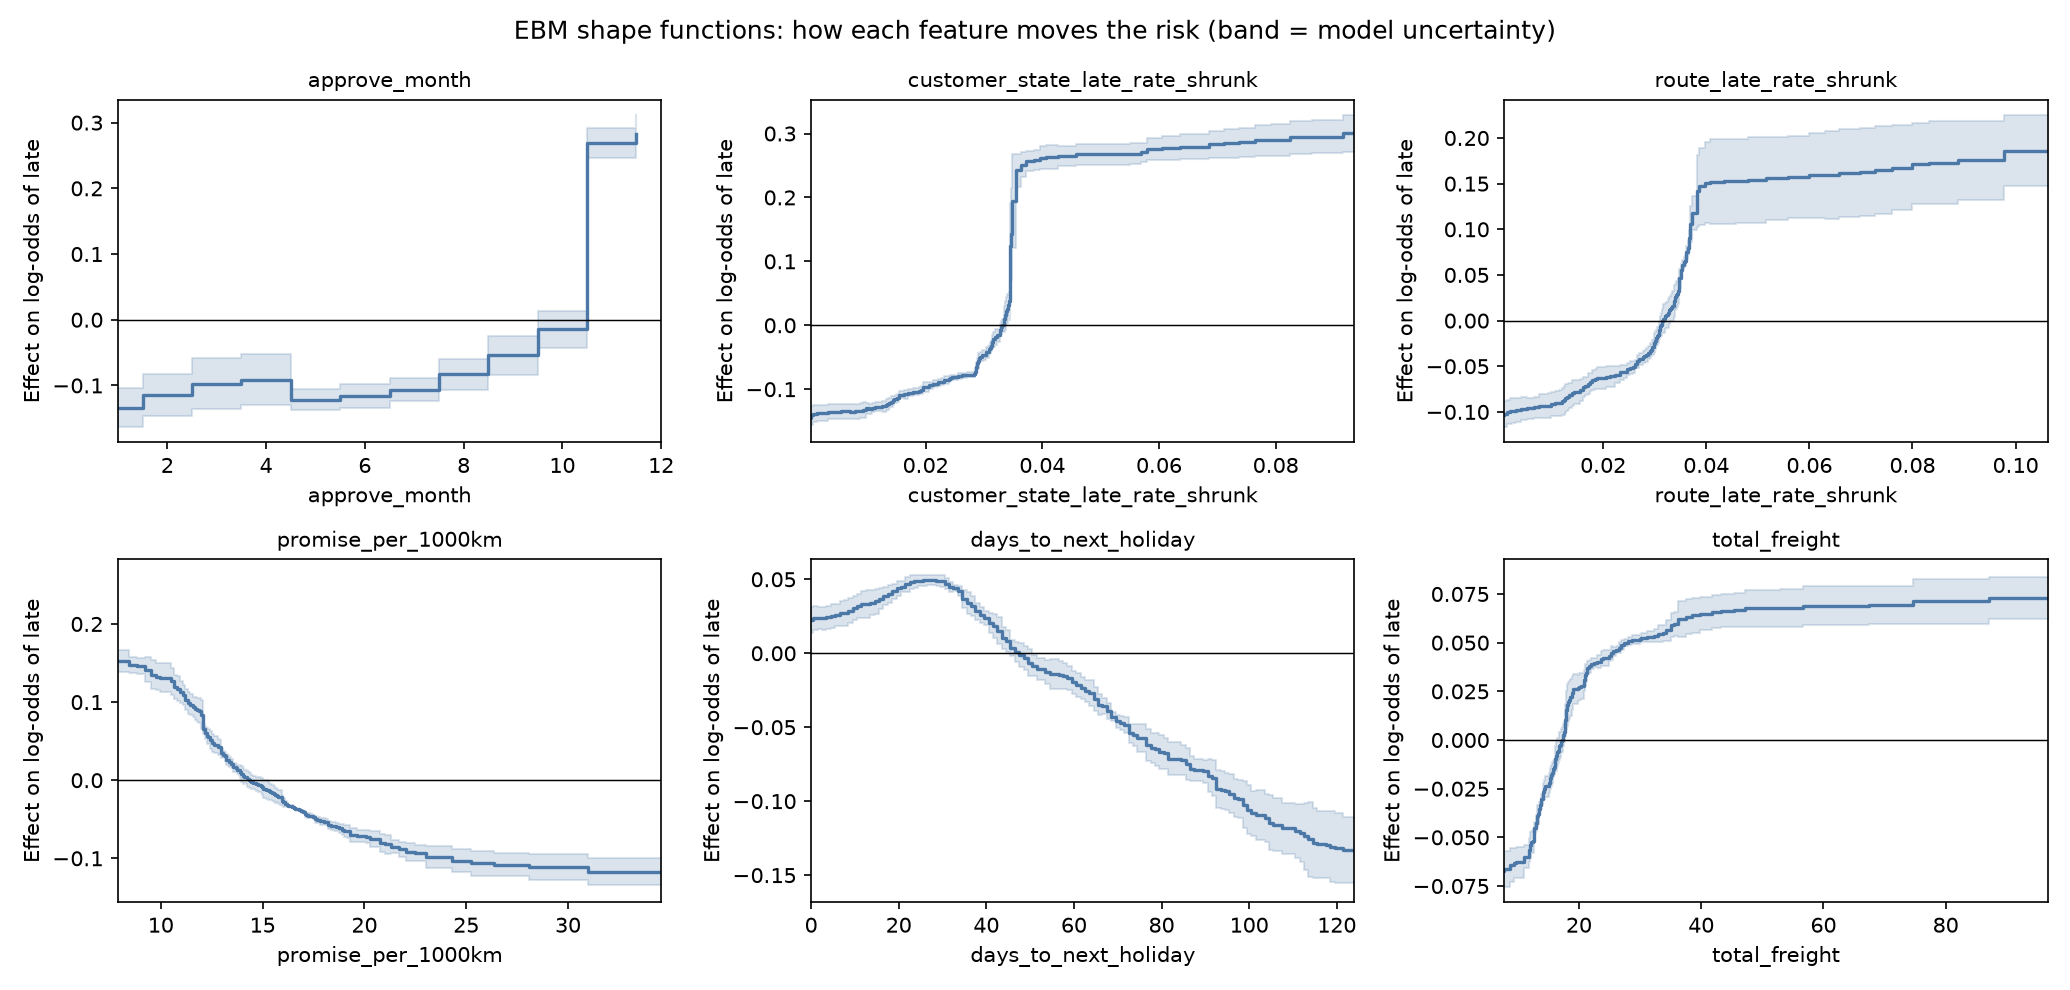

In [4]:
show("explain_ebm_shapes.png")

**How to read it.**
- A curve that rises with the value means "more of this -> more risk".
- Flat stretches mean the model sees no difference between those values.
- Steep jumps mark thresholds the data supports (for example a route's historical late rate
  crossing a few percent).

In [5]:
terms = pd.read_csv(REP / "ebm_term_importance.csv")
inter = terms[terms["kind"] == "interaction"]
Markdown(f"""
**Inference.**
- **Main effects dominate.** The pairwise terms carry only
  **{summary["agreement"]["ebm_interaction_share_of_importance"]:.0%}** of the EBM's total importance; the strongest is
  `{summary["agreement"]["ebm_top_interaction"]}`.
- The strongest interaction is purely calendar-based (`approve_month` x `days_to_next_holiday`).
  The training data covers about one seasonal cycle and one large surge, so this is better read
  as *"which part of the year the training data happened to cover"* than as a business rule.
- The next-strongest interactions pair a history rate with distance, promise or region
  (for example `promise_per_1000km` x `customer_state_late_rate_shrunk`): the effect of a long
  trip depends on how reliable the destination has been.
""")


**Inference.**
- **Main effects dominate.** The pairwise terms carry only
  **28%** of the EBM's total importance; the strongest is
  `approve_month & days_to_next_holiday`.
- The strongest interaction is purely calendar-based (`approve_month` x `days_to_next_holiday`).
  The training data covers about one seasonal cycle and one large surge, so this is better read
  as *"which part of the year the training data happened to cover"* than as a business rule.
- The next-strongest interactions pair a history rate with distance, promise or region
  (for example `promise_per_1000km` x `customer_state_late_rate_shrunk`): the effect of a long
  trip depends on how reliable the destination has been.


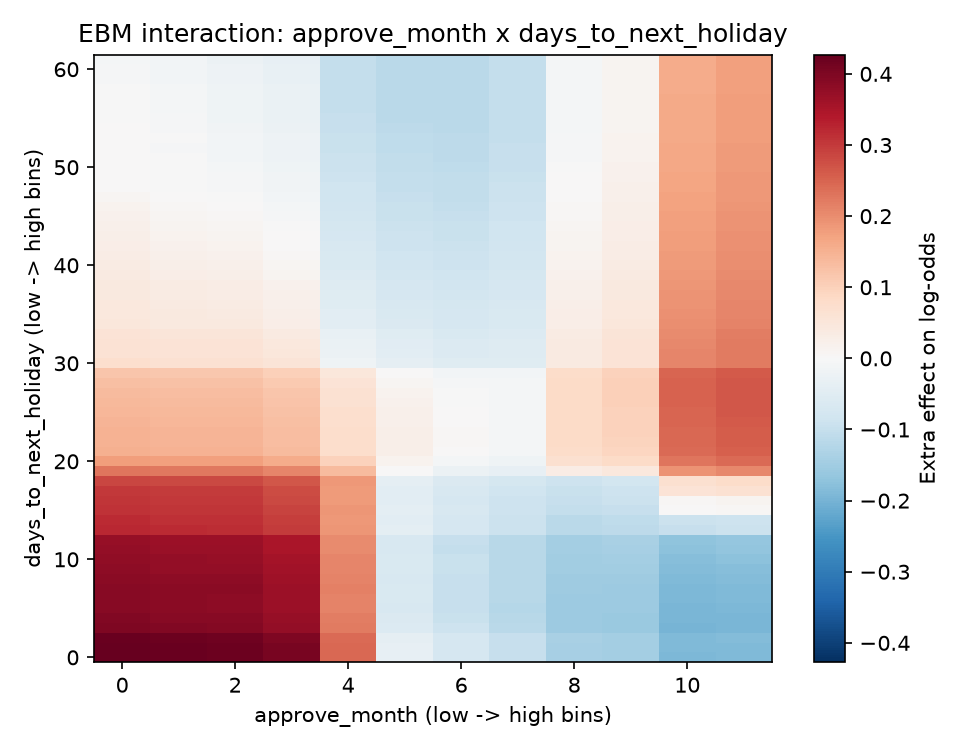

In [6]:
show("explain_ebm_interaction.png")

## 3. SHAP for LightGBM (global view)
SHAP gives each feature its Shapley value: its average marginal contribution to a prediction over all
orderings of the features. In the beeswarm every dot is one order; colour is the feature's value
(red high, blue low); horizontal position is its effect on the prediction.

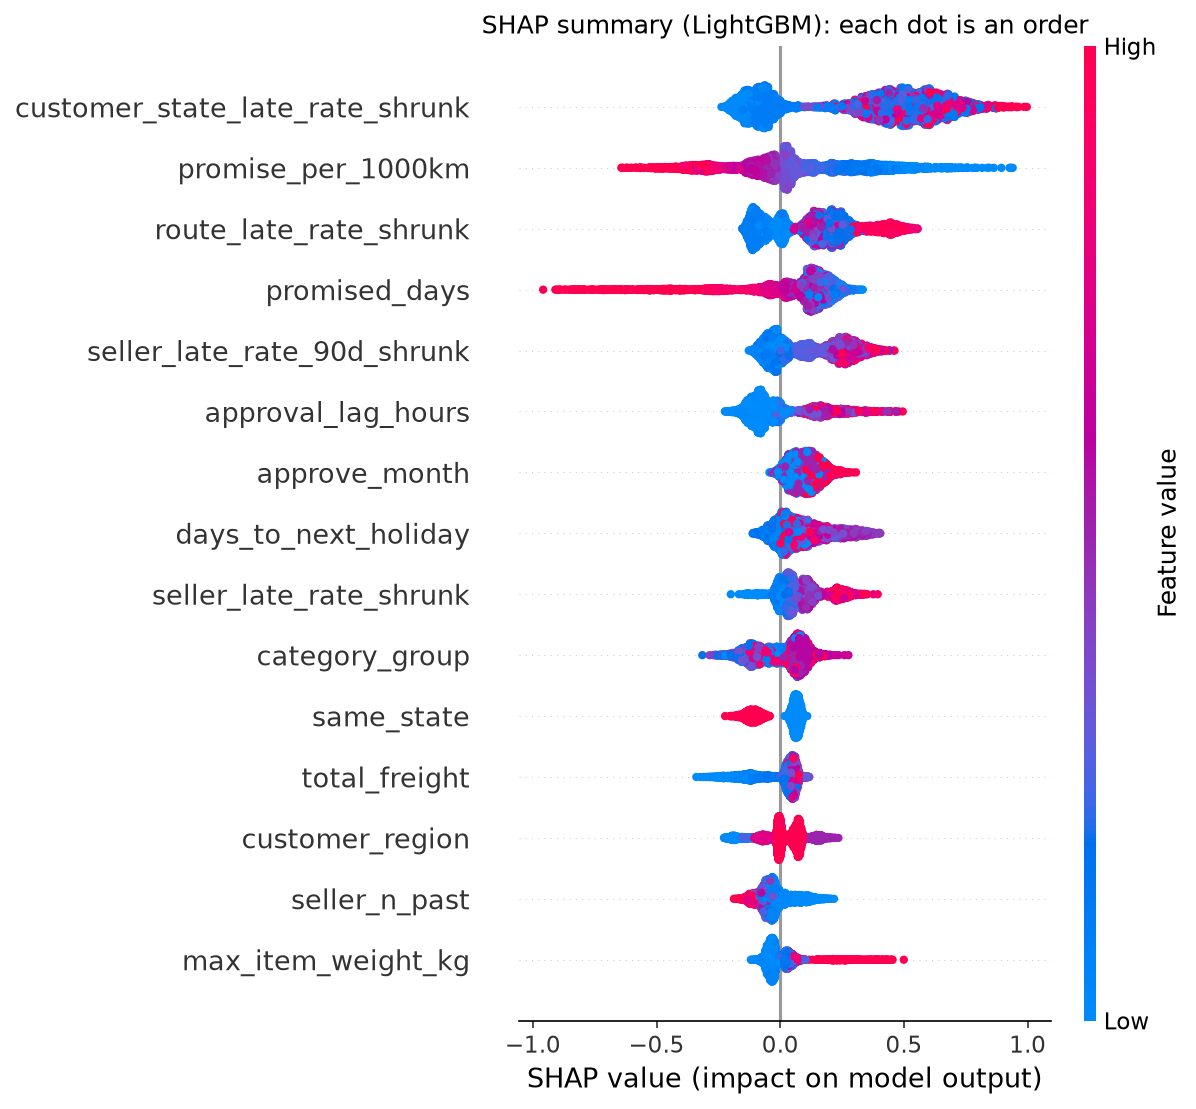

In [7]:
show("explain_shap_beeswarm.png")

In [8]:
top_feats = summary["agreement"]["top10_by_model"]["lightgbm"][:5]
Markdown(
    "**Most important individual features (LightGBM, mean |SHAP|):** "
    + ", ".join(f"`{f}`" for f in top_feats)
)

**Most important individual features (LightGBM, mean |SHAP|):** `customer_state_late_rate_shrunk`, `promise_per_1000km`, `route_late_rate_shrunk`, `promised_days`, `seller_late_rate_90d_shrunk`

**Inference.** The top features are exactly the "history" features (late rates of the customer's state, of
the route and of the seller) together with promise-versus-distance features. Red dots (high
late-rate history) sit to the right (more risk), as intuition says. The dependence plots below
show shape and interactions for the top numeric features.

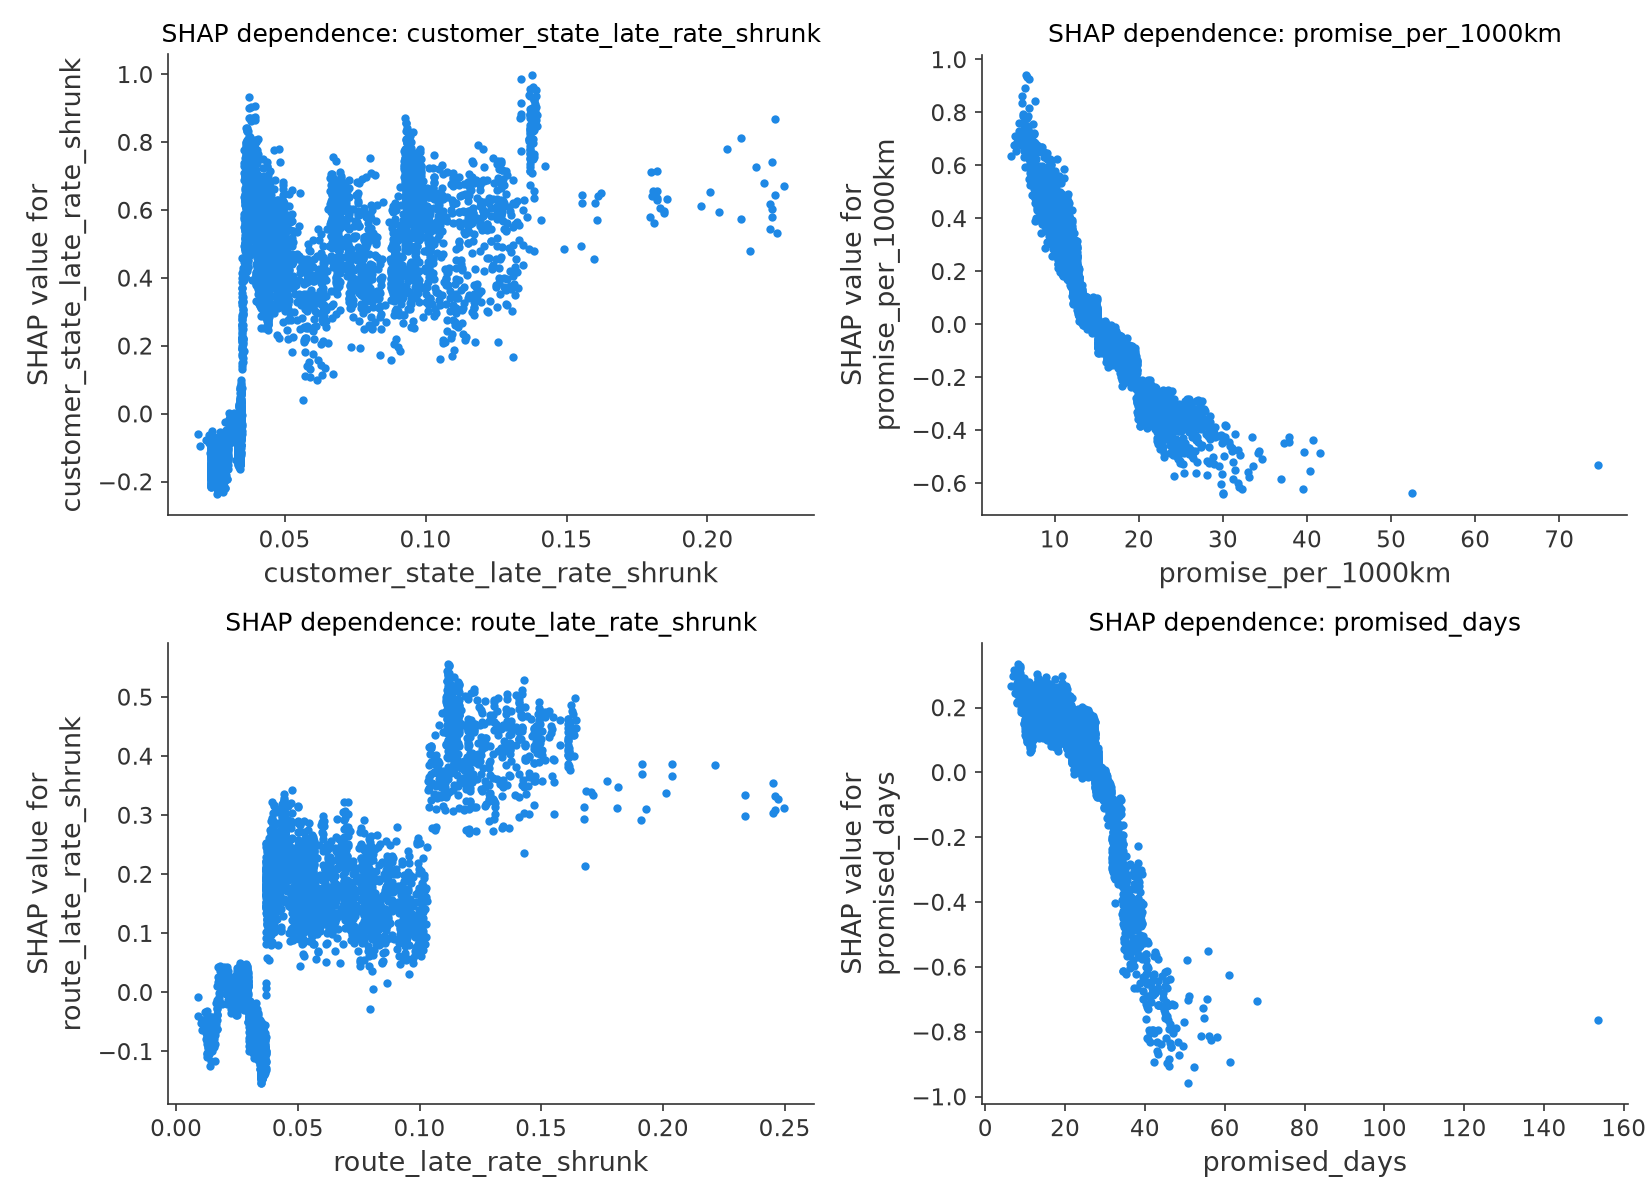

In [9]:
show("explain_shap_dependence.png")

## 4. Do the methods agree on direction? (and where they do not)
For each numeric feature we check whether "higher value" pushes risk up or down in each model,
and compare with the *marginal* direction (the raw relationship with lateness, one feature at a
time).

In [10]:
d = summary["agreement"]["direction"]
dirs = pd.read_csv(REP / "explain_direction_agreement.csv")
conf = dirs[dirs["feature"].isin(d["conflicting_features"] + d["differs_from_marginal"])]
display(conf[["feature", "marginal", "logreg", "lightgbm", "ebm"]].drop_duplicates("feature"))
Markdown(f"""
**Inference.**
- Of **{d["features_compared"]}** numeric features with a clear direction in at least two models,
  **{d["agree"]}** agree on direction and **{d["conflict"]}** conflict.
- Features whose conditional direction differs from the one-feature-at-a-time direction:
  **{", ".join(d["differs_from_marginal"]) or "none"}**.
- Three of those four are calendar features (`approve_month`, `days_to_next_holiday`,
  `holidays_in_promise_window`) - exactly the features most exposed to "one period of history".
- The models also disagree with each other on **{", ".join(d["conflicting_features"])}**. Several
  of these have close siblings (`total_weight_kg` with `max_item_weight_kg` and `total_volume_l`;
  `seller_n_past` with the seller late-rate features), and correlated siblings can receive opposite
  signs. Summing siblings into one reason group means a user never sees two contradictory
  messages about the same idea.
- **Practical rule adopted:** reason sentences state the order's *facts* and let the model's
  contribution sign decide "adds / reduces risk"; they never claim a feature is "high" or "tight"
  because the learned direction can differ from intuition.
""")

,feature,marginal,logreg,lightgbm,ebm
3,geo_imputed,flat/non-monotone,higher value -> more risk,not used,higher value -> less risk
7,handling_window_days,flat/non-monotone,higher value -> more risk,higher value -> less risk,higher value -> less risk
11,approve_month,higher value -> less risk,higher value -> more risk,higher value -> more risk,higher value -> more risk
13,days_to_next_holiday,higher value -> more risk,higher value -> more risk,higher value -> more risk,higher value -> less risk
14,holidays_in_promise_window,higher value -> less risk,higher value -> more risk,higher value -> more risk,flat/non-monotone
19,freight_ratio,higher value -> more risk,higher value -> more risk,higher value -> less risk,higher value -> less risk
20,total_weight_kg,flat/non-monotone,higher value -> less risk,higher value -> more risk,higher value -> more risk
25,seller_n_past,flat/non-monotone,higher value -> less risk,higher value -> less risk,higher value -> more risk



**Inference.**
- Of **32** numeric features with a clear direction in at least two models,
  **26** agree on direction and **6** conflict.
- Features whose conditional direction differs from the one-feature-at-a-time direction:
  **approve_month, days_to_next_holiday, holidays_in_promise_window, freight_ratio**.
- Three of those four are calendar features (`approve_month`, `days_to_next_holiday`,
  `holidays_in_promise_window`) - exactly the features most exposed to "one period of history".
- The models also disagree with each other on **geo_imputed, handling_window_days, days_to_next_holiday, freight_ratio, total_weight_kg, seller_n_past**. Several
  of these have close siblings (`total_weight_kg` with `max_item_weight_kg` and `total_volume_l`;
  `seller_n_past` with the seller late-rate features), and correlated siblings can receive opposite
  signs. Summing siblings into one reason group means a user never sees two contradictory
  messages about the same idea.
- **Practical rule adopted:** reason sentences state the order's *facts* and let the model's
  contribution sign decide "adds / reduces risk"; they never claim a feature is "high" or "tight"
  because the learned direction can differ from intuition.


## 5. From contributions to a sentence
This is the exact procedure used for every one of the 24,093 test orders (all three models):

1. Get per-feature contributions (above).
2. Add up the features that belong to the same reason group (`configs/reason_templates.yaml`).
3. Keep the **top 3 risk-increasing** and **top 2 risk-decreasing** groups whose size is at least
   0.05 log-odds.
4. Fill the group's sentence with the order's own values and append *(adds risk)* / *(reduces risk)*.

In [11]:
rows = []
for g, spec in templates["groups"].items():
    rows.append(
        {
            "reason group": g,
            "features summed": ", ".join(spec["features"]),
            "sentence template": spec.get("text", spec.get("positive")),
        }
    )
display(pd.DataFrame(rows).set_index("reason group").head(8))
codes = ctx["codes"]
share = {m: (codes[codes["model"] == m]["risk_factors"].map(len) > 0).mean() for m in MODEL_NAMES}
Markdown(
    "**Orders with at least one risk factor shown:** "
    + "; ".join(f"{MODEL_NAMES[m]} {pct(v)}" for m, v in share.items())
)

,features summed,sentence template
reason group,,
distance,"distance_km, log_distance_km, promise_per_1000km","Seller-to-customer distance is {distance_km:,.0f} km"
promise_window,"promised_days, handling_window_days","Delivery promise is {promised_days:.1f} days, with {handling_window_days:.1f} days for the seller to hand ..."
destination_region,customer_region,Delivery is to the {customer_region_name} region
origin_region,seller_region,Shipment starts in the {seller_region_name} region
same_state,same_state,Seller and customer are {route_phrase}
route_history,"route_late_rate_shrunk, customer_state_late_rate_shrunk","On this seller-state to customer-state route, about {route_late_rate_shrunk:.0%} of earlier orders arrived..."
seller_record,"seller_n_past, seller_late_rate_shrunk, seller_late_rate_90d_shrunk, seller_days_since_first_order","Seller's record: an estimated {seller_late_rate_90d_shrunk:.0%} late over the last 90 days, {seller_n_past..."
seller_load,seller_load_7d,Seller received {seller_load_7d:.0f} orders in the last 7 days


**Orders with at least one risk factor shown:** Logistic regression 100%; LightGBM 100%; EBM 100%

## 6. Case studies
Cases are chosen **mechanically** from the test set by the primary model's score - no cherry-picking:

- **True positive:** the late order it was most sure about.
- **False positive:** the on-time order it scored highest.
- **False negative:** the late order it scored lowest.

For each case: what happened, what each model said, the plain-English reasons, and a waterfall
that adds up SHAP values from the average prediction to this order's prediction.

### Case 1 - True positive  (order `d115642fba30...`)

,value
outcome,LATE
route,SP -> RJ
distance_km,595
promised_days,6.700
actual_delivery_days,15.200
seller past orders,114
seller 90d late rate (est.),11%
route late rate (est.),15%
category,home_furnishing
approved,2018-08-03 08:15


model,Logistic regression,LightGBM,EBM
predicted probability,0.619,0.118,0.139


**Logistic regression**

- On this seller-state to customer-state route, about 15% of earlier orders arrived late (adds risk)
- Delivery promise is 6.7 days, with 4.0 days for the seller to hand over (adds risk)
- Seller-to-customer distance is 595 km (adds risk)
- Order approved on a Friday in August at 8:00, 16 h after purchase (reduces risk)
- Paid by credit_card in up to 10 instalment(s) (reduces risk)

**LightGBM**

- On this seller-state to customer-state route, about 15% of earlier orders arrived late (adds risk)
- Seller-to-customer distance is 595 km (adds risk)
- Seller's record: an estimated 11% late over the last 90 days, 114 completed orders so far (adds risk)
- Network-wide, 2% of deliveries in the last 30 days were late (reduces risk)
- Order approved on a Friday in August at 8:00, 16 h after purchase (reduces risk)

**EBM**

- On this seller-state to customer-state route, about 15% of earlier orders arrived late (adds risk)
- Seller-to-customer distance is 595 km (adds risk)
- Seller's record: an estimated 11% late over the last 90 days, 114 completed orders so far (adds risk)

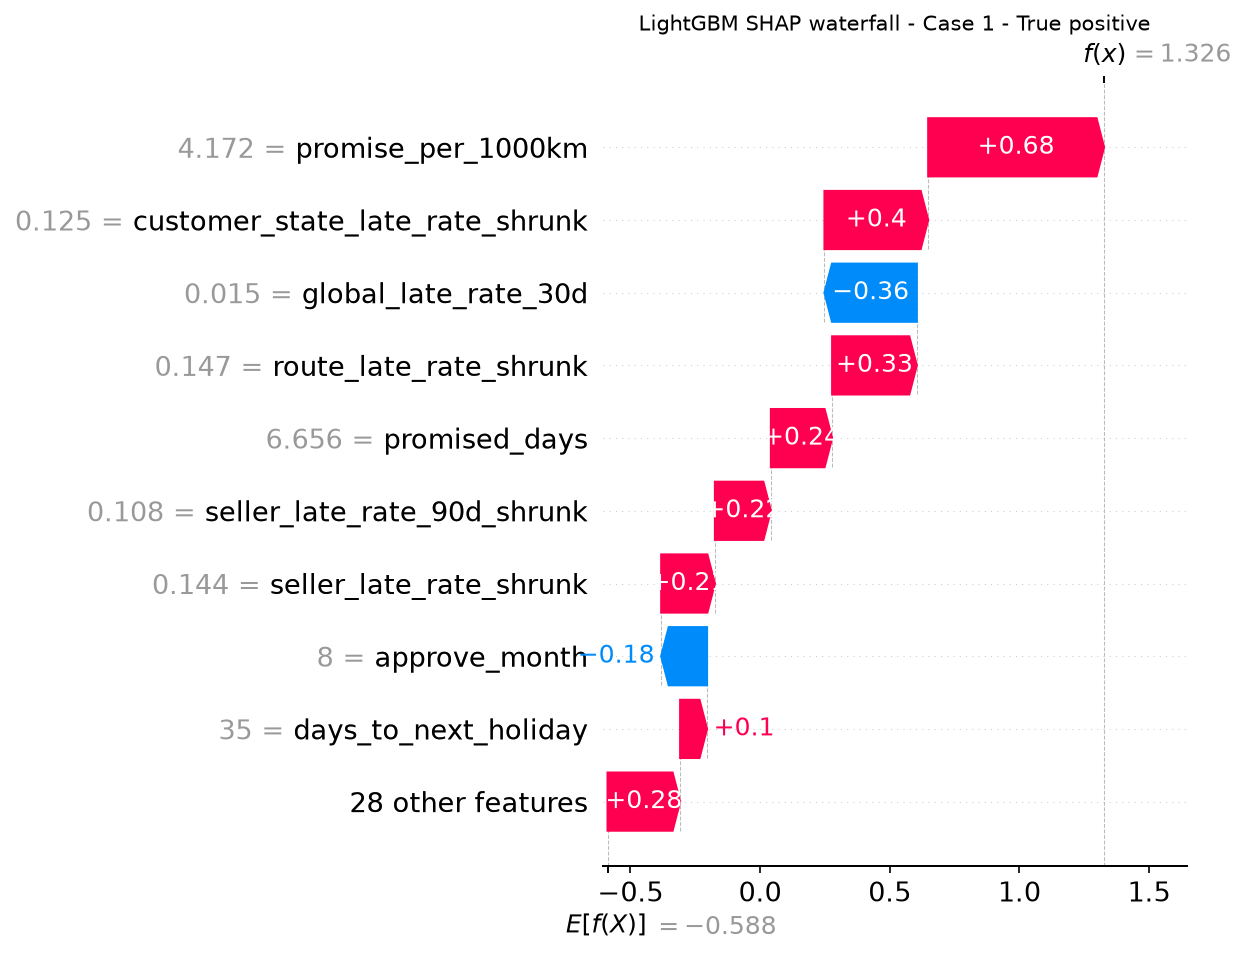

In [12]:
cases = pick_cases(ctx["codes"])
summ = {k: case_summary(ctx, o) for k, o in cases.items()}


def case_facts(s):
    r = s["row"]
    return pd.Series(
        {
            "outcome": "LATE" if s["is_late"] else "on time",
            "route": f"{r.seller_state} -> {r.customer_state}",
            "distance_km": round(r.distance_km),
            "promised_days": round(r.promised_days, 1),
            "actual_delivery_days": round(r.delivery_days, 1),
            "seller past orders": int(r.seller_n_past),
            "seller 90d late rate (est.)": f"{r.seller_late_rate_90d_shrunk:.0%}",
            "route late rate (est.)": f"{r.route_late_rate_shrunk:.0%}",
            "category": r.category_group,
            "approved": str(r.approved_at)[:16],
        }
    )


def show_case(key, title):
    s = summ[key]
    display(Markdown(f"### {title}  (order `{cases[key][:12]}...`)"))
    display(case_facts(s).to_frame("value"))
    probs = pd.DataFrame(
        {
            "model": [MODEL_NAMES[m] for m in s["probability"]],
            "predicted probability": list(s["probability"].values()),
        }
    )
    display(probs.set_index("model").T)
    for m in ["logreg", "lightgbm", "ebm"]:
        display(Markdown(f"**{MODEL_NAMES[m]}**"))
        lines = [f"- {t}" for t in s["risk"][m]] + [f"- {t}" for t in s["protective"][m]]
        display(Markdown("\n".join(lines) if lines else "_no group above the threshold_"))
    # waterfall for LightGBM
    contrib, base = ctx["contribs"]["lightgbm"]
    i = s["idx"]
    path = FIG / f"case_{key}_waterfall.png"
    shap_explain.waterfall(
        contrib.iloc[i].to_numpy(),
        base,
        ctx["X"].iloc[i],
        FEATURE_COLUMNS,
        path,
        f"LightGBM SHAP waterfall - {title}",
    )
    display(Image(filename=str(path)))


show_case("true_positive", "Case 1 - True positive")

In [13]:
tp = summ["true_positive"]
Markdown(f"""
**Reading case 1.** The order was late (**{tp["row"].delivery_days:.1f} days** against a promise of
**{tp["row"].promised_days:.1f}**). Logistic regression gave it **{tp["probability"]["logreg"]:.0%}**; LightGBM
**{tp["probability"]["lightgbm"]:.0%}** and the EBM **{tp["probability"]["ebm"]:.0%}**. All three methods name the
same lead reason - the route's history of late deliveries - and then differ on the next ones.
That is what agreement looks like in practice: the *first* explanation is stable, the long tail is not.

Note the spread: the same order is "62%" for one model and "12-14%" for the others. Absolute
probabilities from the primary model are overconfident at the very top (Phase 7 calibration plot),
which is why the app shows **risk bands and rank**, not a precise percentage.
""")


**Reading case 1.** The order was late (**15.2 days** against a promise of
**6.7**). Logistic regression gave it **62%**; LightGBM
**12%** and the EBM **14%**. All three methods name the
same lead reason - the route's history of late deliveries - and then differ on the next ones.
That is what agreement looks like in practice: the *first* explanation is stable, the long tail is not.

Note the spread: the same order is "62%" for one model and "12-14%" for the others. Absolute
probabilities from the primary model are overconfident at the very top (Phase 7 calibration plot),
which is why the app shows **risk bands and rank**, not a precise percentage.


### Case 2 - False positive  (order `afd8111e2263...`)

,value
outcome,on time
route,SP -> MA
distance_km,2344
promised_days,18.100
actual_delivery_days,11.800
seller past orders,17
seller 90d late rate (est.),21%
route late rate (est.),20%
category,sports_leisure
approved,2018-05-09 20:32


model,Logistic regression,LightGBM,EBM
predicted probability,0.620,0.108,0.081


**Logistic regression**

- On this seller-state to customer-state route, about 20% of earlier orders arrived late (adds risk)
- Seller's record: an estimated 21% late over the last 90 days, 17 completed orders so far (adds risk)
- Seller-to-customer distance is 2,344 km (adds risk)
- Order approved on a Wednesday in May at 20:00, 24 h after purchase (reduces risk)
- Network-wide, 14% of deliveries in the last 30 days were late (reduces risk)

**LightGBM**

- On this seller-state to customer-state route, about 20% of earlier orders arrived late (adds risk)
- Seller-to-customer distance is 2,344 km (adds risk)
- Seller's record: an estimated 21% late over the last 90 days, 17 completed orders so far (adds risk)
- Next public holiday is 121 day(s) after approval and 0 fall in the delivery window (reduces risk)
- Product category is sports leisure (reduces risk)

**EBM**

- On this seller-state to customer-state route, about 20% of earlier orders arrived late (adds risk)
- Seller-to-customer distance is 2,344 km (adds risk)
- Seller's record: an estimated 21% late over the last 90 days, 17 completed orders so far (adds risk)
- Next public holiday is 121 day(s) after approval and 0 fall in the delivery window (reduces risk)
- Order approved on a Wednesday in May at 20:00, 24 h after purchase (reduces risk)

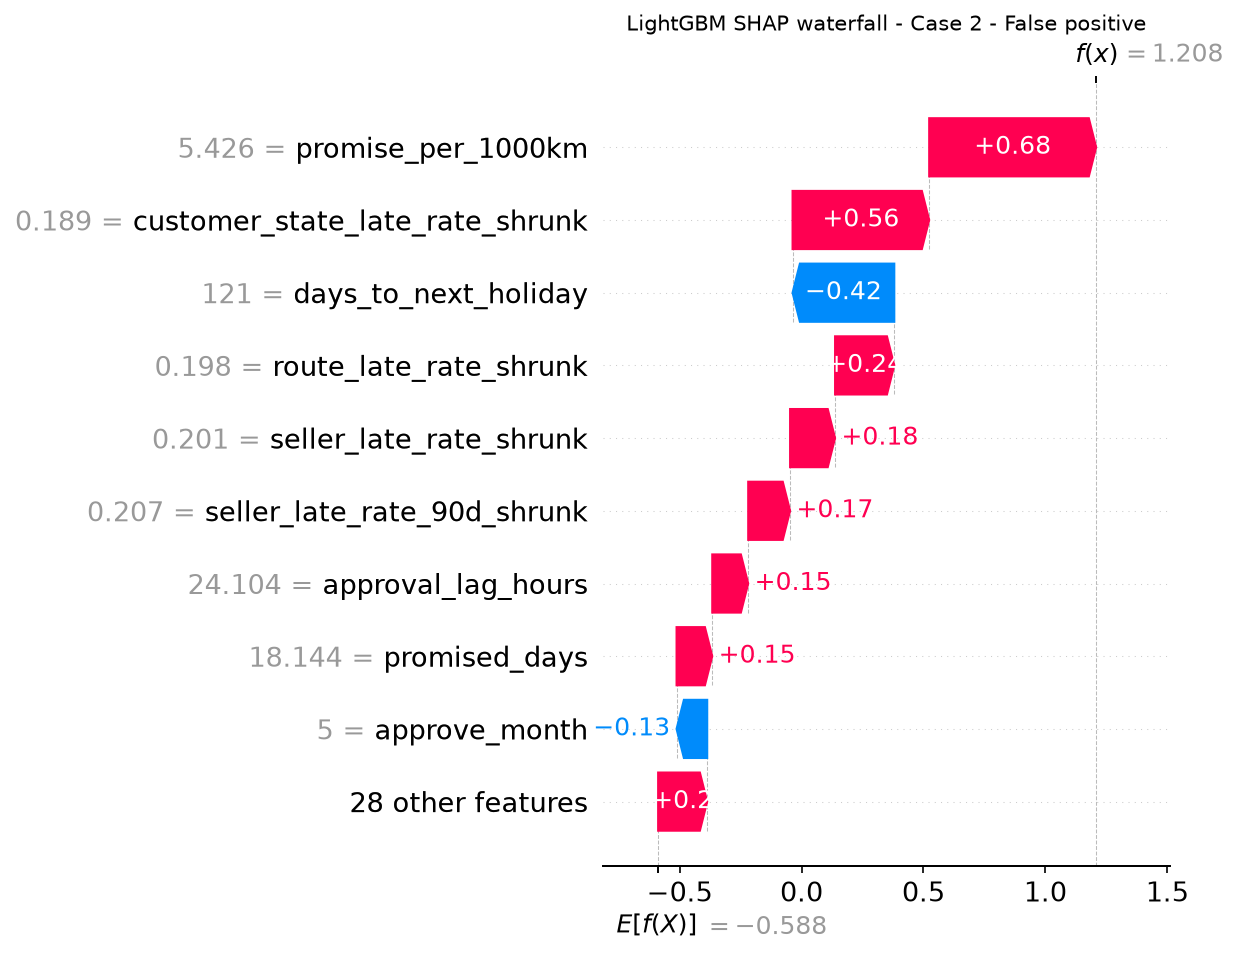

In [14]:
show_case("false_positive", "Case 2 - False positive")

In [15]:
fp = summ["false_positive"]
Markdown(f"""
**Reading case 2.** The order was flagged at **{fp["probability"]["logreg"]:.0%}** but arrived on time -
**{fp["row"].delivery_days:.1f} days** against a promise of **{fp["row"].promised_days:.1f}**.
The reasons the model gave were real facts about the order: a long route
(**{fp["row"].distance_km:,.0f} km**, {fp["row"].seller_state} to {fp["row"].customer_state}), a route whose earlier orders were often late
(**{fp["row"].route_late_rate_shrunk:.0%}**), and a seller with only **{int(fp["row"].seller_n_past)}** completed orders.

Note how differently the models see it: LightGBM gave it only
**{fp["probability"]["lightgbm"]:.0%}** and the EBM **{fp["probability"]["ebm"]:.0%}**. Much of this "false positive"
is the linear model's over-confidence at the top end, not a failure of the reasons: the
route, seller and distance facts are real and all three models cite them.
A high score is a *ranking* signal ("riskier than most orders today"), not a verdict.
A good false positive is one whose reasons were reasonable - which these are.
""")


**Reading case 2.** The order was flagged at **62%** but arrived on time -
**11.8 days** against a promise of **18.1**.
The reasons the model gave were real facts about the order: a long route
(**2,344 km**, SP to MA), a route whose earlier orders were often late
(**20%**), and a seller with only **17** completed orders.

Note how differently the models see it: LightGBM gave it only
**11%** and the EBM **8%**. Much of this "false positive"
is the linear model's over-confidence at the top end, not a failure of the reasons: the
route, seller and distance facts are real and all three models cite them.
A high score is a *ranking* signal ("riskier than most orders today"), not a verdict.
A good false positive is one whose reasons were reasonable - which these are.


### Case 3 - False negative  (order `6d05d2deb6a5...`)

,value
outcome,LATE
route,PR -> PR
distance_km,353
promised_days,27.300
actual_delivery_days,36.200
seller past orders,138
seller 90d late rate (est.),7%
route late rate (est.),2%
category,gifts_stationery_arts
approved,2018-07-05 16:17


model,Logistic regression,LightGBM,EBM
predicted probability,0.006,0.028,0.028


**Logistic regression**

- Seller's record: an estimated 7% late over the last 90 days, 138 completed orders so far (adds risk)
- Next public holiday is 64 day(s) after approval and 0 fall in the delivery window (adds risk)
- On this seller-state to customer-state route, about 2% of earlier orders arrived late (adds risk)
- Order approved on a Thursday in July at 16:00, 56 h after purchase (reduces risk)
- Seller and customer are in the same state (reduces risk)

**LightGBM**

- On this seller-state to customer-state route, about 2% of earlier orders arrived late (adds risk)
- Seller's record: an estimated 7% late over the last 90 days, 138 completed orders so far (adds risk)
- Seller-to-customer distance is 353 km (reduces risk)
- Product category is gifts stationery arts (reduces risk)

**EBM**

- On this seller-state to customer-state route, about 2% of earlier orders arrived late (adds risk)
- Seller's record: an estimated 7% late over the last 90 days, 138 completed orders so far (adds risk)
- Shipment starts in the South region (reduces risk)
- Seller and customer are in the same state (reduces risk)

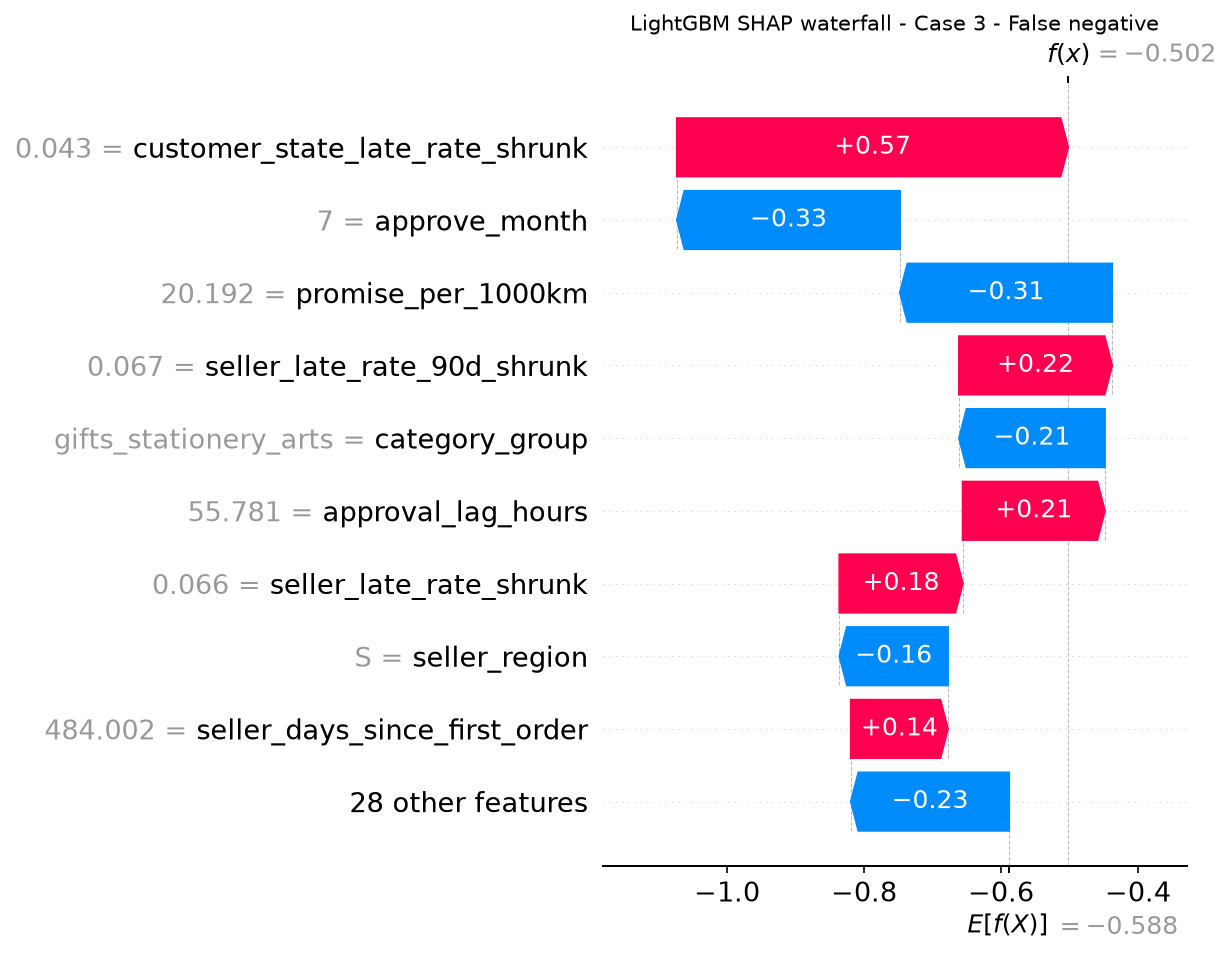

In [16]:
show_case("false_negative", "Case 3 - False negative")

In [17]:
fn = summ["false_negative"]
Markdown(f"""
**Reading case 3.** This order took **{fn["row"].delivery_days:.1f} days** against a promise of
**{fn["row"].promised_days:.1f}** and all three models scored it below **{max(fn["probability"].values()):.0%}**.
What the model saw: a short route inside one state ({fn["row"].seller_state} to {fn["row"].customer_state},
{fn["row"].distance_km:,.0f} km), an established seller (**{int(fn["row"].seller_n_past)}** completed orders) and
a route with a very low historical late rate (**{fn["row"].route_late_rate_shrunk:.0%}**).

Everything knowable at approval time said "safe". Whatever delayed this parcel (a carrier incident,
a stock-out, an address problem) is **not in the data available at approval**. No explanation method
can recover information the model never had; this is the irreducible part of the problem and the
reason prediction is paired with *capacity-limited* intervention rather than promised certainty.
""")


**Reading case 3.** This order took **36.2 days** against a promise of
**27.3** and all three models scored it below **3%**.
What the model saw: a short route inside one state (PR to PR,
353 km), an established seller (**138** completed orders) and
a route with a very low historical late rate (**2%**).

Everything knowable at approval time said "safe". Whatever delayed this parcel (a carrier incident,
a stock-out, an address problem) is **not in the data available at approval**. No explanation method
can recover information the model never had; this is the irreducible part of the problem and the
reason prediction is paired with *capacity-limited* intervention rather than promised certainty.


## 7. What the explanations tell us - and what they do not
**What we can say**
- The system relies mostly on route and seller history and on how long the promise is relative to
  distance. Three different explanation methods agree on this.
- Reasons shown to users are exact decompositions of the model's output (verified to
  floating-point precision in the tests), phrased as facts.

**What we should not say**
- *Causal claims.* "Route history adds risk" means the model uses it that way, not that changing
  the route history would change lateness.
- *Stable business rules from calendar features.* `approve_month` and the holiday features
  mostly encode the period the model was trained on.
- *Precise percentages.* Probabilities are overconfident at the top end and shift with the
  base rate; use risk bands and rank.

**Follow-ups this suggests (not done in this phase):** drop `approve_month` and the holiday proxy
features in a v2 and re-validate; examine whether the strong payment-type weight in the linear
model is a stable effect or a time-specific artefact; collapse collinear history features.